## Cell 1 — Finite-horizon LQR via explicit Bellman iterations

We consider a discrete-time LTI system $x_{k+1} = A x_k + B u_k$ where $A$ has an **unstable node at the origin** (eigenvalues outside the unit disk, i.e. $A$ is not Schur). We solve the finite-horizon LQR problem

$$
\min_{u_0,\dots,u_{N-1}} \; x_N^\top P_N x_N + \sum_{k=0}^{N-1} \big( x_k^\top Q x_k + u_k^\top R u_k \big),
\qquad P_N = Q,
$$

by running the **Bellman (Riccati) recursion backwards in time**:

$$
P_k = Q + A^\top P_{k+1} A - A^\top P_{k+1} B\,(R + B^\top P_{k+1} B)^{-1} B^\top P_{k+1} A,
\qquad
K_k = (R + B^\top P_{k+1} B)^{-1} B^\top P_{k+1} A.
$$

We use a short horizon ($N = 10$) and **print every gain $K_k$**, then simulate the closed-loop system from a couple of initial conditions. Note that finite-horizon gains are **time-varying** and, for a short horizon on an unstable plant, are *not* guaranteed to stabilize the system — that is expected behavior, not a bug.

Eigenvalues of A: [1.2 1.3]
Spectral radius: 1.3 (>1 => unstable)

Finite-horizon LQR gains K_k (k=0..N-1):
  k= 0: K = [0.14   1.5557]
  k= 1: K = [0.3137 1.1872]
  k= 2: K = [0.4317 0.937 ]
  k= 3: K = [0.5107 0.7693]
  k= 4: K = [0.5633 0.6577]
  k= 5: K = [0.5984 0.5832]
  k= 6: K = [0.6221 0.5318]
  k= 7: K = [0.6376 0.4918]
  k= 8: K = [0.6359 0.4452]
  k= 9: K = [0.5333 0.3333]

P_0 (final converged cost):
 [[ 37.1015 -74.8475]
 [-74.8475 160.9773]]


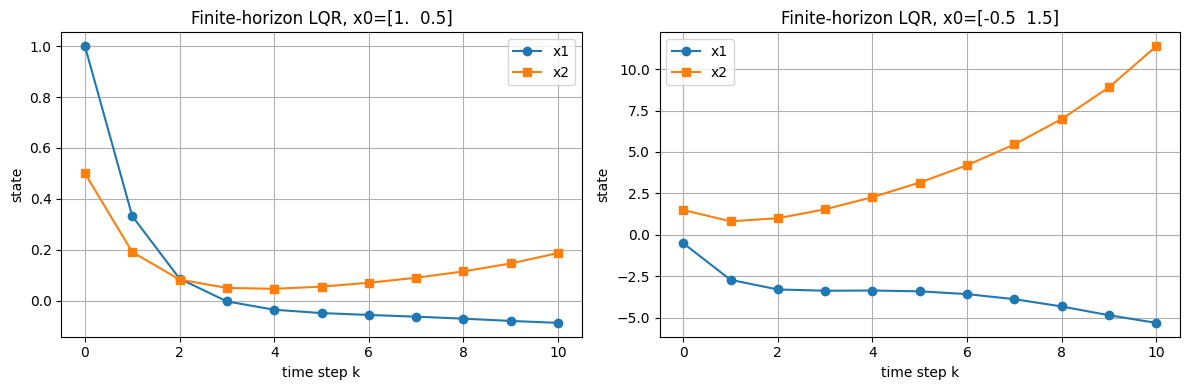

In [10]:
# ============================================================
# Finite-horizon LQR via explicit Bellman iterations
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

# Discrete-time LTI system x_{k+1} = A x_k + B u_k
# A has an unstable node at the origin (eigenvalues outside unit circle)
A = np.array([[1.2, 0.1],
              [0.0, 1.3]])
B = np.array([[1.0],
              [0.5]])
Q = np.eye(2)          # state cost
R = np.array([[1.0]])  # control cost

# Verify A is not Schur
eigs = np.linalg.eigvals(A)
print("Eigenvalues of A:", eigs)
print("Spectral radius:", max(abs(eigs)), "(>1 => unstable)\n")

#########################
# Finite horizon
N = 10
# N = 100 #<-- try this setting for actual convergence
#########################

P = Q.copy()           # terminal cost P_N = Q
Ks = [None] * N        # store gains K_0 ... K_{N-1}
Ps = [None] * (N + 1)  # store P_0 ... P_N
Ps[N] = P.copy()

# Backward Bellman iterations: P_k = Q + A^T P_{k+1} A - A^T P_{k+1} B (R + B^T P_{k+1} B)^{-1} B^T P_{k+1} A
for k in range(N - 1, -1, -1):
    Pn = Ps[k + 1]
    S = R + B.T @ Pn @ B
    K = np.linalg.solve(S, B.T @ Pn @ A)
    Pk = Q + A.T @ Pn @ A - A.T @ Pn @ B @ K
    Ks[k] = K
    Ps[k] = Pk

print("Finite-horizon LQR gains K_k (k=0..N-1):")
for k, K in enumerate(Ks):
    print(f"  k={k:2d}: K = {K.ravel()}")

print("\nP_0 (final converged cost):\n", Ps[0])

# Simulate trajectories
def simulate(A, B, K, x0, N):
    x = np.zeros((N + 1, len(x0)))
    u = np.zeros((N, B.shape[1]))
    x[0] = x0
    for k in range(N):
        u[k] = -K @ x[k]
        x[k + 1] = A @ x[k] + B @ u[k]
    return x, u

x0_list = [np.array([1.0, 0.5]), np.array([-0.5, 1.5])]
time = np.arange(N + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, x0 in enumerate(x0_list):
    x = np.zeros((N + 1, 2))
    x[0] = x0
    for k in range(N):
        x[k + 1] = A @ x[k] + B @ (-Ks[k] @ x[k])
    axes[i].plot(time, x[:, 0], 'o-', label='x1')
    axes[i].plot(time, x[:, 1], 's-', label='x2')
    axes[i].set_title(f"Finite-horizon LQR, x0={x0}")
    axes[i].set_xlabel("time step k")
    axes[i].set_ylabel("state")
    axes[i].grid(True)
    axes[i].legend()
plt.tight_layout()
plt.show()

## Cell 2 — Infinite-horizon LQR

For the same system, we now solve the **infinite-horizon** LQR problem, which amounts to finding the stabilizing solution of the **discrete algebraic Riccati equation (DARE)**

$$
P = Q + A^\top P A - A^\top P B\,(R + B^\top P B)^{-1} B^\top P A,
$$

using `scipy.linalg.solve_discrete_are`. The optimal steady-state gain is then

$$
K_\infty = (R + B^\top P_\infty B)^{-1} B^\top P_\infty A,
$$

and the closed loop $A_{cl} = A - B K_\infty$ is guaranteed to have all eigenvalues strictly inside the unit disk. We print $P_\infty$, $K_\infty$, the closed-loop eigenvalues, and plot trajectories from the same initial conditions used in Cell 1 so the two designs can be compared directly.

Infinite-horizon P:
 [[  495.4943 -1047.1081]
 [-1047.1081  2223.1619]]

Infinite-horizon K:
 [[-6.5045 15.6488]]
Closed-loop eigenvalues: [0.8064 0.3737]
Spectral radius: 0.8064114034771706 (<1 => stable)



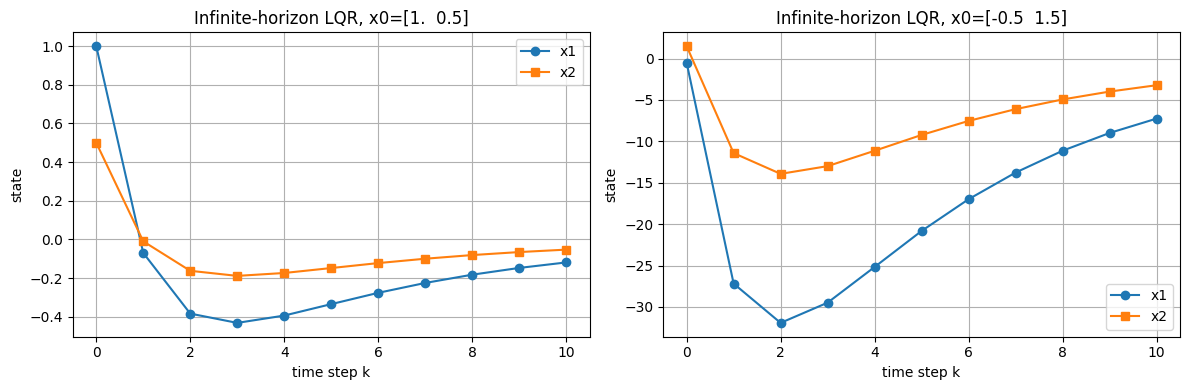

In [11]:
# ============================================================
# Infinite-horizon LQR (solve discrete algebraic Riccati)
# ============================================================
from scipy.linalg import solve_discrete_are

# Solve DARE: P = Q + A^T P A - A^T P B (R + B^T P B)^{-1} B^T P A
P_inf = solve_discrete_are(A, B, Q, R)
K_inf = np.linalg.solve(R + B.T @ P_inf @ B, B.T @ P_inf @ A)

print("Infinite-horizon P:\n", P_inf)
print("\nInfinite-horizon K:\n", K_inf)

# Closed-loop eigenvalues
Acl = A - B @ K_inf
print("Closed-loop eigenvalues:", np.linalg.eigvals(Acl))
print("Spectral radius:", max(abs(np.linalg.eigvals(Acl))), "(<1 => stable)\n")

# Simulate
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, x0 in enumerate(x0_list):
    x = np.zeros((N + 1, 2))
    x[0] = x0
    for k in range(N):
        x[k + 1] = A @ x[k] + B @ (-K_inf @ x[k])
    axes[i].plot(time, x[:, 0], 'o-', label='x1')
    axes[i].plot(time, x[:, 1], 's-', label='x2')
    axes[i].set_title(f"Infinite-horizon LQR, x0={x0}")
    axes[i].set_xlabel("time step k")
    axes[i].set_ylabel("state")
    axes[i].grid(True)
    axes[i].legend()
plt.tight_layout()
plt.show()

## Cell 3 — Lyapunov certificate from $P_\infty$

The infinite-horizon Riccati solution $P_\infty$ gives a **quadratic Lyapunov function**

$$
V(x) = x^\top P_\infty x .
$$

We verify the two conditions for a valid Lyapunov certificate of asymptotic stability of the closed loop $x_{k+1} = A_{cl} x_k$:

1. **Positive definiteness:** $P_\infty \succ 0$ (all eigenvalues $> 0$), so $V(x) > 0$ for $x \neq 0$.
2. **Strict decrease (discrete-time):**
$$
\Delta V(x) = V(A_{cl} x) - V(x) = x^\top \big( A_{cl}^\top P_\infty A_{cl} - P_\infty \big) x < 0 \quad \forall x \neq 0,
$$
which holds iff $A_{cl}^\top P_\infty A_{cl} - P_\infty \prec 0$ (all eigenvalues $< 0$).

We check both conditions via eigenvalue analysis, then plot the surfaces $V(x)$ and $\Delta V(x)$ together with level sets of $V$ and closed-loop trajectories — the trajectories must cross the level sets *inward*, confirming the certificate visually.

Eigenvalues of P (must all be > 0 for V>0): [   1.8878 2716.7684]
P positive definite: True

Eigenvalues of Acl^T P Acl - P (must all be < 0): [-288.1926   -1.    ]
ΔV negative definite: True

Verification x^T M x < 0 for random samples: True


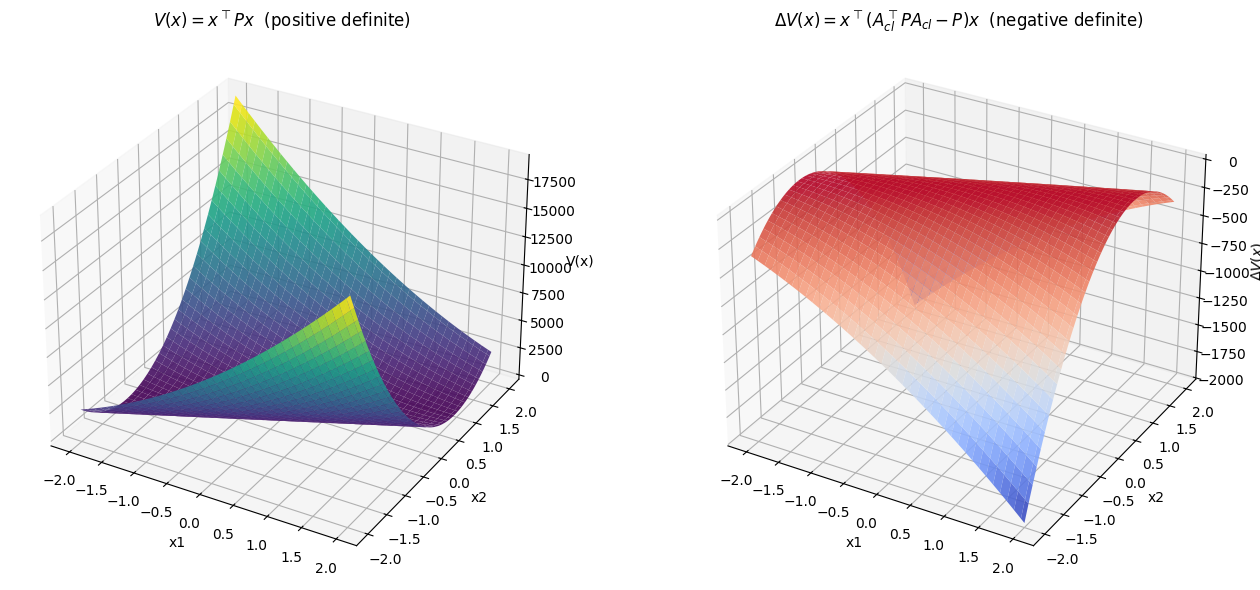

In [13]:
# ============================================================
# Lyapunov certificate from P_inf, and surface plots
# ============================================================
from mpl_toolkits.mplot3d import Axes3D  # noqa

# Candidate Lyapunov function V(x) = x^T P x
# For discrete-time: ΔV(x) = V(Acl x) - V(x) = x^T (Acl^T P Acl - P) x
Acl = A - B @ K_inf
P = P_inf

# Check V > 0: P must be positive definite
eig_P = np.linalg.eigvalsh(P)
print("Eigenvalues of P (must all be > 0 for V>0):", eig_P)
print("P positive definite:", np.all(eig_P > 0))

# Check discrete decrease: Acl^T P Acl - P must be negative definite
Delta = Acl.T @ P @ Acl - P
eig_D = np.linalg.eigvalsh(Delta)
print("\nEigenvalues of Acl^T P Acl - P (must all be < 0):", eig_D)
print("ΔV negative definite:", np.all(eig_D < 0))

# Alternatively, in continuous-time interpretation: V̇ ≈ (Acl^T P + P Acl) < 0.
# Since we are in discrete time, we use the discrete decrease condition above.
# For contrast, the continuous-time "derivative" along x_{k+1}=Acl x_k flow:
M = Acl.T @ P @ Acl - P
print("\nVerification x^T M x < 0 for random samples:",
      all(x @ M @ x < 0 for x in np.random.randn(1000, 2)))

# Plot surfaces for V and ΔV
xs = np.linspace(-2, 2, 80)
ys = np.linspace(-2, 2, 80)
X, Y = np.meshgrid(xs, ys)
Z = np.zeros_like(X)
W = np.zeros_like(X)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        xv = np.array([X[i, j], Y[i, j]])
        Z[i, j] = xv @ P @ xv          # V(x) = x^T P x
        W[i, j] = xv @ M @ xv          # ΔV(x)

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)
ax1.set_title(r"$V(x) = x^\top P x$  (positive definite)")
ax1.set_xlabel("x1"); ax1.set_ylabel("x2"); ax1.set_zlabel("V(x)")

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(X, Y, W, cmap='coolwarm', edgecolor='none', alpha=0.9)
ax2.set_title(r"$\Delta V(x) = x^\top(A_{cl}^\top P A_{cl}-P)x$  (negative definite)")
ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.set_zlabel(r"$\Delta V(x)$")

plt.tight_layout()
plt.show()

# # Contour check: level sets of V are ellipses, and trajectories cross them inward
# fig, ax = plt.subplots(figsize=(6, 6))
# cs = ax.contour(X, Y, Z, levels=10, cmap='viridis')
# ax.clabel(cs, inline=True, fontsize=8)
# for x0 in x0_list:
#     x = np.zeros((N + 1, 2))
#     x[0] = x0
#     for k in range(N):
#         x[k + 1] = Acl @ x[k]
#     ax.plot(x[:, 0], x[:, 1], 'r-o', markersize=4, label=f"x0={x0}")
# ax.set_title("Level sets of V and closed-loop trajectories (inward crossing)")
# ax.set_xlabel("x1"); ax.set_ylabel("x2")
# ax.axis('equal'); ax.grid(True); ax.legend()
# plt.show()